## Model Implementation with Full Inverse-frequency Weighted Loss Functions

1. Loading the preprocessed data from data_preprocessing_actual.ipynb

In [17]:
import pandas as pd
import numpy as np
from pathlib import Path

# getting the folder with the preprocessed datasets
data_dir = Path("preprocessed_data")

# features
X_train = pd.read_csv(data_dir / "X_train.csv")
X_validation = pd.read_csv(data_dir / "X_validation.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")

# targets
y_train = pd.read_csv(data_dir / "y_train.csv")
y_validation = pd.read_csv(data_dir / "y_validation.csv")
y_test = pd.read_csv(data_dir / "y_test.csv")

In [18]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense
tf.keras.utils.set_random_seed(42)
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

2. Prepare the input and target arrays

Converting the preprocessed DataFrames and separating the two prediction tasks.

In [19]:
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_validation.to_numpy(dtype=np.float32)

# 11 binary complication
binary_cols = [
    col for col in y_train.columns
    if col != "LET_IS"
]
y_train_binary = y_train[binary_cols].to_numpy(dtype=np.float32)
y_val_binary = y_validation[binary_cols].to_numpy(dtype=np.float32)

# 8-class categorical target
y_train_let = y_train["LET_IS"].to_numpy(dtype=np.int32)
y_val_let = y_validation["LET_IS"].to_numpy(dtype=np.int32)

assert len(binary_cols) == 11
assert np.isfinite(X_train_np).all()
assert np.isfinite(X_val_np).all()
assert np.isfinite(y_train_binary).all()
assert np.isfinite(y_val_binary).all()
assert set(np.unique(y_train_binary)).issubset({0, 1})
assert set(np.unique(y_val_binary)).issubset({0, 1})
assert np.all((y_train_let >= 0) & (y_train_let < 8))
assert np.all((y_val_let >= 0) & (y_val_let < 8))


3. Calculating the positive class weigths

In [20]:
# get the counts for the positive and negative examples
positive_counts = y_train_binary.sum(axis=0)
negative_counts = len(y_train_binary) - positive_counts

# weighting positive examples more heavily
positive_weights = (negative_counts / np.maximum(positive_counts, 1)).astype(np.float32)

# Display weights
weights_df = pd.DataFrame({
    "Complication": binary_cols,
    "Positive Count": positive_counts.astype(int),
    "Negative Count": negative_counts.astype(int),
    "Positive Weight": positive_weights
})

display(weights_df.round(2))


,Complication,Positive Count,Negative Count,Positive Weight
0,FIBR_PREDS,119,1071,9.000000
1,PREDS_TAH,14,1176,84.000000
2,JELUD_TAH,29,1161,40.029999
3,FIBR_JELUD,50,1140,22.799999
4,A_V_BLOK,40,1150,28.750000
5,OTEK_LANC,111,1079,9.720000
6,RAZRIV,38,1152,30.320000
7,DRESSLER,53,1137,21.450001
8,ZSN,276,914,3.310000
9,REC_IM,111,1079,9.720000


Calculate weights for LET_IS

In [21]:
classes = np.arange(8)

let_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_let
).astype(np.float32)

print("LET_IS class weights:")

for cls, weight in enumerate(let_class_weights):
    print(f"Class {cls}: {weight:.3f}")


LET_IS class weights:
Class 0: 0.149
Class 1: 1.932
Class 2: 11.442
Class 3: 3.914
Class 4: 9.297
Class 5: 18.594
Class 6: 7.829
Class 7: 7.829


4. Creating the weighted loss functions so the model can account for the imbalance

In [22]:
pos_weights_tf = tf.constant(
    positive_weights,
    dtype=tf.float32
)

let_weights_tf = tf.constant(
    let_class_weights,
    dtype=tf.float32
)

def weighted_binary_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)

    # converting probabilities to logits
    y_pred = tf.clip_by_value(
        y_pred, 1e-7, 1 - 1e-7
    )
    logits = tf.math.log(y_pred / (1 - y_pred))

    # weight positive examples for each complication
    loss = tf.nn.weighted_cross_entropy_with_logits(
        labels=y_true,
        logits=logits,
        pos_weight=pos_weights_tf
    )

    return tf.reduce_mean(loss, axis=-1)

def weighted_let_loss(y_true, y_pred):
    y_true = tf.cast(
        tf.reshape(y_true, [-1]),
        tf.int32
    )

    # categorical loss per patient
    loss = tf.keras.losses.sparse_categorical_crossentropy(
        y_true, y_pred
    )

    # applying the class-specific weights
    sample_weights = tf.gather(
        let_weights_tf, y_true
    )

    return loss * sample_weights


5. Building the Multi-class MLP

In [23]:
# the input layer
inputs = Input(
    shape=(X_train_np.shape[1],),
    name="clinical_features"
)

# shared hidden layers
x = Dense(64, activation="relu")(inputs)
x = Dense(32, activation="relu")(x)

# 11 binary complications branch
binary_output = Dense(
    11,
    activation="sigmoid",
    name="complications"
)(x)

# 8-class LET_IS outcome branch
let_output = Dense(
    8,
    activation="softmax",
    name="let_is"
)(x)

# the multitask model
weighted_model = Model(
    inputs=inputs,
    outputs=[binary_output, let_output]
)


6. Compiling the model

In [24]:
weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss={
        "complications": weighted_binary_loss,
        "let_is": weighted_let_loss
    },
    metrics={
        "complications": [
            tf.keras.metrics.BinaryAccuracy(
                name="binary_accuracy"
            )
        ],
        "let_is": [
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            )
        ]
    }
)


The optimizer remains Adam, with a learning rate of 0.001.

The difference is that the weighted losses penalize mistakes involving rare complications and outcomes more heavily.

7. Training the model with early stopping

We use early stopping to reduce unnecessary training and restore the weights from the epoch with the lowest validation loss.

In [25]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

weighted_history = weighted_model.fit(
    X_train_np,
    {
        "complications": y_train_binary,
        "let_is": y_train_let
    },
    validation_data=(
        X_val_np,
        {
            "complications": y_val_binary,
            "let_is": y_val_let
        }
    ),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - complications_binary_accuracy: 0.4982 - complications_loss: 1.3173 - let_is_accuracy: 0.0563 - let_is_loss: 2.0649 - loss: 3.4235 - val_complications_binary_accuracy: 0.4788 - val_complications_loss: 1.3011 - val_let_is_accuracy: 0.1451 - val_let_is_loss: 2.0452 - val_loss: 3.3149
Epoch 2/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - complications_binary_accuracy: 0.4734 - complications_loss: 1.2822 - let_is_accuracy: 0.2008 - let_is_loss: 1.9061 - loss: 3.2264 - val_complications_binary_accuracy: 0.4631 - val_complications_loss: 1.2945 - val_let_is_accuracy: 0.2863 - val_let_is_loss: 2.0166 - val_loss: 3.2800
Epoch 3/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - complications_binary_accuracy: 0.4826 - complications_loss: 1.2686 - let_is_accuracy: 0.2916 - let_is_loss: 1.8011 - loss: 3.1058 - val_complications_binary_accuracy: 0.4895 - val_complications_loss: 1.2895 - val_let_is_accuracy: 0.3843 - val_let_is_loss: 1.9937 - val_loss: 3.252

8. Plotting the Training and Validation losses

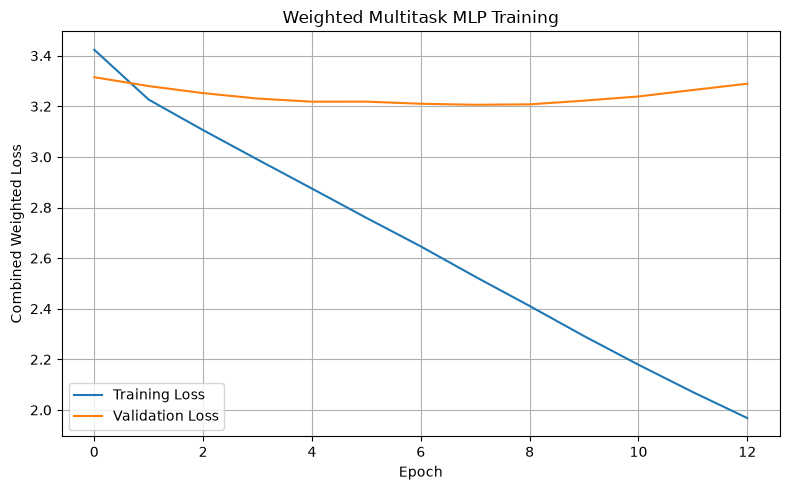

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    weighted_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    weighted_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Combined Weighted Loss")
plt.title("Weighted Multitask MLP Training")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [27]:
print("Initial training loss:",
      weighted_history.history["loss"][0])

print("Final training loss:",
      weighted_history.history["loss"][-1])

print("Initial validation loss:",
      weighted_history.history["val_loss"][0])

print("Final validation loss:",
      weighted_history.history["val_loss"][-1])

print("Epochs trained:",
      len(weighted_history.history["loss"]))


Initial training loss: 3.4234554767608643
Final training loss: 1.967987060546875
Initial validation loss: 3.3149280548095703
Final validation loss: 3.2893130779266357
Epochs trained: 13


9. Checking predictions across the entire validation set

In [29]:
# predicting all validation patients
weighted_binary_probs, weighted_let_probs = (
    weighted_model.predict(X_val_np)
)

# converting probabilities to predictions
weighted_binary_preds = (
    weighted_binary_probs >= 0.5
).astype(int)

weighted_let_preds = np.argmax(
    weighted_let_probs,
    axis=1
)

# positive predictions per complication
print("Positive predictions per complication:")

for i, col in enumerate(binary_cols):
    print(
        f"{col}: {weighted_binary_preds[:, i].sum()}"
    )

# LET_IS class distribution
print("\nLET_IS predicted class distribution:")

print(
    pd.Series(weighted_let_preds)
    .value_counts()
    .sort_index()
)


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Positive predictions per complication:
FIBR_PREDS: 92
PREDS_TAH: 127
JELUD_TAH: 71
FIBR_JELUD: 80
A_V_BLOK: 71
OTEK_LANC: 170
RAZRIV: 45
DRESSLER: 121
ZSN: 99
REC_IM: 104
P_IM_STEN: 145

LET_IS predicted class distribution:
0    137
1     15
2      9
3     42
4     20
5      2
6      7
7     23
Name: count, dtype: int64


10. Checking actual vs predicted complications

In [30]:
comparison = pd.DataFrame({
    "Complication": binary_cols,
    "Actual Positives": y_val_binary.sum(axis=0).astype(int),
    "Predicted Positives": weighted_binary_preds.sum(axis=0)
})

display(comparison)

print("\nActual LET_IS distribution:")
print(
    pd.Series(y_val_let)
    .value_counts()
    .sort_index()
)

print("\nPredicted LET_IS distribution:")
print(
    pd.Series(weighted_let_preds)
    .value_counts()
    .sort_index()
)


,Complication,Actual Positives,Predicted Positives
0,FIBR_PREDS,26,92
1,PREDS_TAH,3,127
2,JELUD_TAH,7,71
3,FIBR_JELUD,11,80
4,A_V_BLOK,8,71
5,OTEK_LANC,24,170
6,RAZRIV,8,45
7,DRESSLER,11,121
8,ZSN,59,99
9,REC_IM,24,104



Actual LET_IS distribution:
0    215
1     16
2      3
3      8
4      3
5      2
6      4
7      4
Name: count, dtype: int64

Predicted LET_IS distribution:
0    137
1     15
2      9
3     42
4     20
5      2
6      7
7     23
Name: count, dtype: int64


11. Checking the confusion matrix

In [31]:
results = []

for i, col in enumerate(binary_cols):
    tn, fp, fn, tp = confusion_matrix(
        y_val_binary[:, i],
        weighted_binary_preds[:, i],
        labels=[0, 1]
    ).ravel()

    results.append({
        "Complication": col,
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "True Negatives": tn
    })

confusion_df = pd.DataFrame(results)

display(confusion_df)


,Complication,True Positives,False Positives,False Negatives,True Negatives
0,FIBR_PREDS,15,77,11,152
1,PREDS_TAH,0,127,3,125
2,JELUD_TAH,3,68,4,180
3,FIBR_JELUD,4,76,7,168
4,A_V_BLOK,4,67,4,180
5,OTEK_LANC,15,155,9,76
6,RAZRIV,3,42,5,205
7,DRESSLER,9,112,2,132
8,ZSN,27,72,32,124
9,REC_IM,13,91,11,140


Summary

In [32]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# generating predictions using the fully weighted model
full_binary_probs, full_let_probs = weighted_model.predict(X_val_np)

# converting probabilities to predictions
full_binary_preds = (full_binary_probs >= 0.5).astype(int)
full_let_preds = np.argmax(full_let_probs, axis=1)

# metrics for each binary complication
full_metrics_summary = pd.DataFrame({
    "Complication": binary_cols,
    "Accuracy": [
        accuracy_score(y_val_binary[:, i], full_binary_preds[:, i])
        for i in range(len(binary_cols))
    ],
    "Macro Precision": [
        precision_score(
            y_val_binary[:, i], full_binary_preds[:, i],
            average="macro", zero_division=0
        )
        for i in range(len(binary_cols))
    ],
    "Macro Recall": [
        recall_score(
            y_val_binary[:, i], full_binary_preds[:, i],
            average="macro", zero_division=0
        )
        for i in range(len(binary_cols))
    ],
    "Macro F1": [
        f1_score(
            y_val_binary[:, i], full_binary_preds[:, i],
            average="macro", zero_division=0
        )
        for i in range(len(binary_cols))
    ]
})

# metrics for LET_IS
full_let_metrics = pd.DataFrame({
    "Complication": ["LET_IS"],
    "Accuracy": [
        accuracy_score(y_val_let, full_let_preds)
    ],
    "Macro Precision": [
        precision_score(
            y_val_let, full_let_preds,
            labels=np.arange(8),
            average="macro", zero_division=0
        )
    ],
    "Macro Recall": [
        recall_score(
            y_val_let, full_let_preds,
            labels=np.arange(8),
            average="macro", zero_division=0
        )
    ],
    "Macro F1": [
        f1_score(
            y_val_let, full_let_preds,
            labels=np.arange(8),
            average="macro", zero_division=0
        )
    ]
})

# binary complications and LET_IS into one table
full_all_metrics_summary = pd.concat(
    [full_metrics_summary, full_let_metrics],
    ignore_index=True
)

display(full_all_metrics_summary.round(4))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Complication,Accuracy,Macro Precision,Macro Recall,Macro F1
0,FIBR_PREDS,0.6549,0.5478,0.6203,0.5149
1,PREDS_TAH,0.4902,0.4883,0.2480,0.3289
2,JELUD_TAH,0.7176,0.5103,0.5772,0.4551
3,FIBR_JELUD,0.6745,0.5050,0.5261,0.4449
4,A_V_BLOK,0.7216,0.5173,0.6144,0.4683
5,OTEK_LANC,0.3569,0.4912,0.4770,0.3178
6,RAZRIV,0.8157,0.5214,0.6025,0.5052
7,DRESSLER,0.5529,0.5297,0.6796,0.4174
8,ZSN,0.5922,0.5338,0.5451,0.5232
9,REC_IM,0.6000,0.5261,0.5739,0.4681


Creating CSV file to use for Baseline comparison

In [33]:
full_all_metrics_summary.to_csv(
    "full_weighting.csv", index=False
)